# Temporal Baseline Model Comparison

This notebook compares Logistic Regression, LightGBM, and XGBoost using one fixed chronological validation partition. Models fit only on `split.train`; parameter selection uses only `split.validation`.

**The holdout partition is not inspected, transformed, predicted, or evaluated. It remains reserved for final evaluation and later production simulation.**

In [1]:
import gc
import sys
from pathlib import Path

import lightgbm as lgb
import mlflow
import pandas as pd
import xgboost as xgb
from IPython.display import Image, display
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from fraud_detection.data import (
    load_train_identity,
    load_train_transaction,
    merge_train_data,
    split_data_chronologically,
    validate_training_data,
)
from fraud_detection.models import (
    TrainingOnlyPreprocessor,
    run_temporal_parameter_search,
    save_model_comparison_plots,
    write_model_comparison_report,
)

2026/10/06 05:40:39 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at C:\fraud-detection-system\.venv\Lib\site-packages\mlflow\assistant\skills\instrumenting-with-mlflow-tracing\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\Marwan\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


## 1. Fixed temporal data design

Random K-fold validation would mix future and past behavior. The existing 70/15/15 chronological split is retained. Only training and validation are referenced after splitting.

In [2]:
raw_dir = PROJECT_ROOT / "data" / "raw"
transaction = load_train_transaction(raw_dir)
identity = load_train_identity(raw_dir)
merged = merge_train_data(transaction, identity)
split = split_data_chronologically(merged)
train = split.train
validation = split.validation
validate_training_data(train)
del transaction, identity, merged
gc.collect()

print(f"Train rows: {len(train):,}")
print(f"Validation rows: {len(validation):,}")
print("Holdout status: reserved and never referenced by the modeling workflow")

Train rows: 413,378
Validation rows: 88,581
Holdout status: reserved and never referenced by the modeling workflow


## 2. Leakage-safe baseline preprocessing

`isFraud` and `TransactionID` are excluded. `TransactionDT` remains as relative time. Numeric medians and categorical frequencies are learned from training only. Frequency encoding keeps high-cardinality fields to one numeric column each, and unseen validation categories map to zero. This is a memory-conscious baselineâ€”not final feature engineering.

In [3]:
excluded_columns = ["isFraud", "TransactionID"]
feature_columns = [column for column in train.columns if column not in excluded_columns]
x_train_frame = train[feature_columns]
x_validation_frame = validation[feature_columns]
y_train = train["isFraud"].astype("int8")
y_validation = validation["isFraud"].astype("int8")
validation_prevalence = float(y_validation.mean())

preprocessor = TrainingOnlyPreprocessor()
x_train = preprocessor.fit_transform(x_train_frame)
x_validation = preprocessor.transform(x_validation_frame)
del x_train_frame, x_validation_frame
gc.collect()

scaler = StandardScaler(copy=False)
x_train = scaler.fit_transform(x_train)
x_validation = scaler.transform(x_validation)
print(f"Predictors: {x_train.shape[1]}")
print(f"Validation prevalence / no-skill PR-AUC: {validation_prevalence:.6f}")

Predictors: 432
Validation prevalence / no-skill PR-AUC: 0.034341


## 3. MLflow experiment and practical grids

Each combination is fit on training and scored once on the fixed validation set. The grids are deliberately small because IEEE-CIS contains hundreds of thousands of rows and 432 baseline predictors.

In [4]:
tracking_uri = f"sqlite:///{(PROJECT_ROOT / 'model_comparison.db').resolve().as_posix()}"
mlflow.set_tracking_uri(tracking_uri)
experiment_name = "fraud-detection-model-comparison"

grids = {
    "Logistic Regression": {"C": [1.0]},
    "LightGBM": {
        "num_leaves": [31, 63],
        "learning_rate": [0.03, 0.1],
        "n_estimators": [400],
    },
    "XGBoost": {
        "max_depth": [4, 7],
        "learning_rate": [0.03, 0.1],
        "n_estimators": [300],
    },
}
grids

{'Logistic Regression': {'C': [1.0]},
 'LightGBM': {'num_leaves': [31, 63],
  'learning_rate': [0.03, 0.1],
  'n_estimators': [400]},
 'XGBoost': {'max_depth': [4, 7],
  'learning_rate': [0.03, 0.1],
  'n_estimators': [300]}}

## 4. Logistic Regression

The linear baseline uses balanced class weights. Frequency encoding avoids an unmanageably wide one-hot matrix. A single full-data `C=1.0` configuration is used because repeated SAGA fits were the dominant runtime cost; the dataset is not subsampled.

In [5]:
logistic_result = run_temporal_parameter_search(
    "Logistic Regression",
    lambda params: LogisticRegression(
        **params,
        solver="saga",
        class_weight="balanced",
        max_iter=100,
        tol=1e-3,
        random_state=42,
        n_jobs=-1,
    ),
    grids["Logistic Regression"],
    x_train,
    y_train,
    x_validation,
    y_validation,
    experiment_name,
)
logistic_result.history

C:\fraud-detection-system\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


2026/10/06 05:43:43 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


,model,parameters,run_id,pr_auc,roc_auc,precision,recall,f1
0,Logistic Regression,{'C': 1.0},723edaee63bc40de9fc325135877a1d4,0.367155,0.836731,0.09027,0.776463,0.161737


## 5. LightGBM

In [6]:
lightgbm_result = run_temporal_parameter_search(
    "LightGBM",
    lambda params: lgb.LGBMClassifier(
        **params,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
        verbosity=-1,
    ),
    grids["LightGBM"],
    x_train,
    y_train,
    x_validation,
    y_validation,
    experiment_name,
)
lightgbm_result.history

2026/10/06 05:45:40 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


,model,parameters,run_id,pr_auc,roc_auc,precision,recall,f1
0,LightGBM,"{'learning_rate': 0.1, 'n_estimators': 400, 'n...",b9c11c3ae13a49afbfc8e4342eff7a81,0.587317,0.921482,0.572638,0.533859,0.552569
1,LightGBM,"{'learning_rate': 0.1, 'n_estimators': 400, 'n...",21d3a09638bf4483b3950592b6bcfe96,0.556940,0.914011,0.365516,0.633465,0.463555
2,LightGBM,"{'learning_rate': 0.03, 'n_estimators': 400, '...",27f33d339d894136aea896f279279b63,0.545271,0.919158,0.275561,0.694609,0.394585
3,LightGBM,"{'learning_rate': 0.03, 'n_estimators': 400, '...",211e91c9f60747ff94b6d36685f54a4e,0.521277,0.909549,0.199241,0.741946,0.314127


## 6. XGBoost

In [7]:
scale_pos_weight = float((y_train == 0).sum() / (y_train == 1).sum())
xgboost_result = run_temporal_parameter_search(
    "XGBoost",
    lambda params: xgb.XGBClassifier(
        **params,
        scale_pos_weight=scale_pos_weight,
        tree_method="hist",
        eval_metric="aucpr",
        random_state=42,
        n_jobs=-1,
    ),
    grids["XGBoost"],
    x_train,
    y_train,
    x_validation,
    y_validation,
    experiment_name,
)
xgboost_result.history

2026/10/06 05:47:52 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


,model,parameters,run_id,pr_auc,roc_auc,precision,recall,f1
0,XGBoost,"{'learning_rate': 0.1, 'max_depth': 7, 'n_esti...",1e0ad5e44daf4081a17620902b55efc6,0.561597,0.913651,0.420699,0.597304,0.493683
1,XGBoost,"{'learning_rate': 0.1, 'max_depth': 4, 'n_esti...",722a6a49370143468026679cc959119e,0.515859,0.900266,0.205990,0.723537,0.320682
2,XGBoost,"{'learning_rate': 0.03, 'max_depth': 7, 'n_est...",82c703e6ecd64b94b023113c9ca641c9,0.509693,0.900721,0.205891,0.721565,0.320368
3,XGBoost,"{'learning_rate': 0.03, 'max_depth': 4, 'n_est...",ed54ebd8f3be4998b138a088fafffdf9,0.467973,0.878681,0.160211,0.727482,0.262593


## 7. Validation comparison

PR-AUC is primary because it focuses on minority-class ranking quality. ROC-AUC and threshold metrics provide complementary views. The 0.50 threshold is not yet optimized for business cost.

In [8]:
results = [logistic_result, lightgbm_result, xgboost_result]
comparison = (
    pd.DataFrame(
        [
            {
                "Model": result.model_name,
                "Best Parameters": result.best_parameters,
                "PR-AUC": result.metrics.pr_auc,
                "ROC-AUC": result.metrics.roc_auc,
                "Precision @ 0.50": result.metrics.precision,
                "Recall @ 0.50": result.metrics.recall,
                "F1 @ 0.50": result.metrics.f1,
            }
            for result in results
        ]
    )
    .sort_values("PR-AUC", ascending=False)
    .reset_index(drop=True)
)
comparison

,Model,Best Parameters,PR-AUC,ROC-AUC,Precision @ 0.50,Recall @ 0.50,F1 @ 0.50
0,LightGBM,"{'learning_rate': 0.1, 'n_estimators': 400, 'n...",0.587317,0.921482,0.572638,0.533859,0.552569
1,XGBoost,"{'learning_rate': 0.1, 'max_depth': 7, 'n_esti...",0.561597,0.913651,0.420699,0.597304,0.493683
2,Logistic Regression,{'C': 1.0},0.367155,0.836731,0.090270,0.776463,0.161737


In [9]:
winner = max(results, key=lambda result: result.metrics.pr_auc)
print(f"BEST VALIDATION MODEL: {winner.model_name}")
print(f"Validation PR-AUC: {winner.metrics.pr_auc:.6f}")
print(f"No-skill PR-AUC: {validation_prevalence:.6f}")

BEST VALIDATION MODEL: LightGBM
Validation PR-AUC: 0.587317
No-skill PR-AUC: 0.034341


## 8. Curves, winner confusion matrix, and report

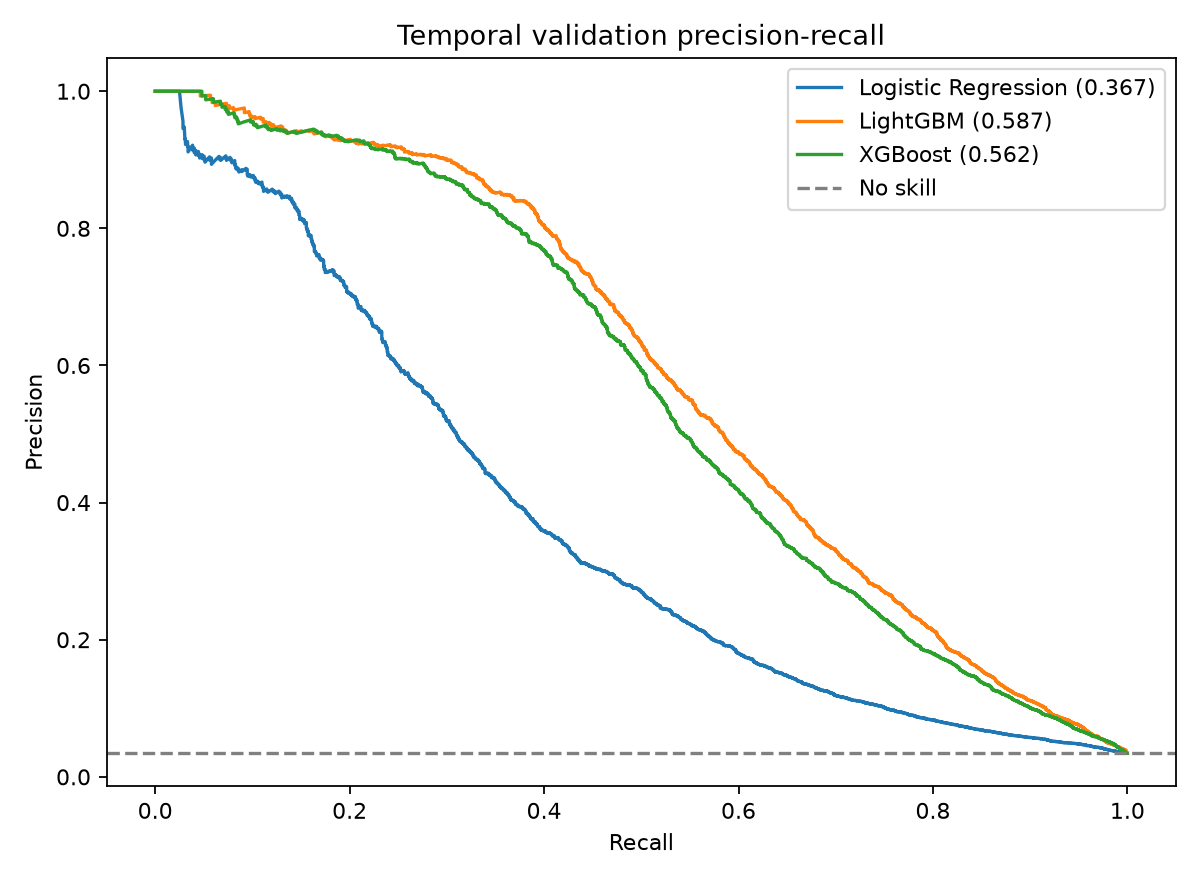

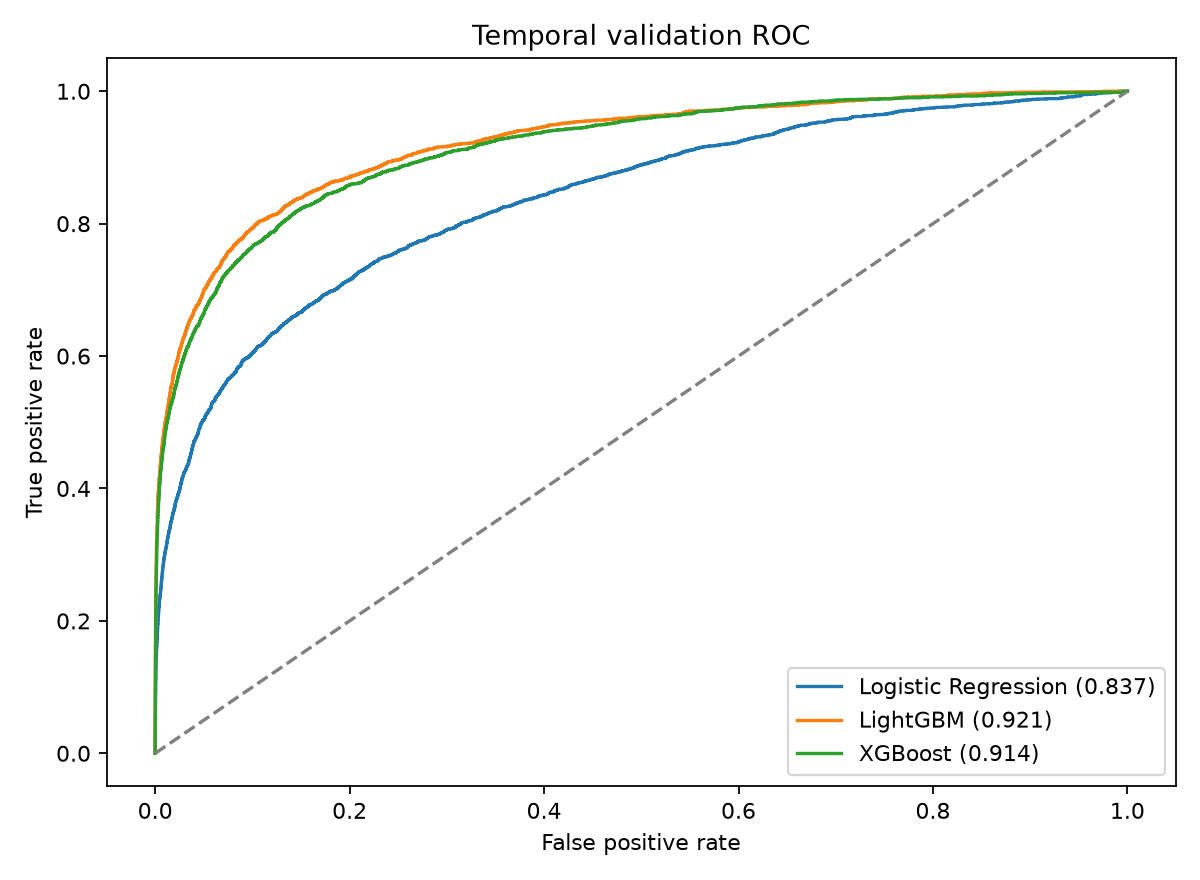

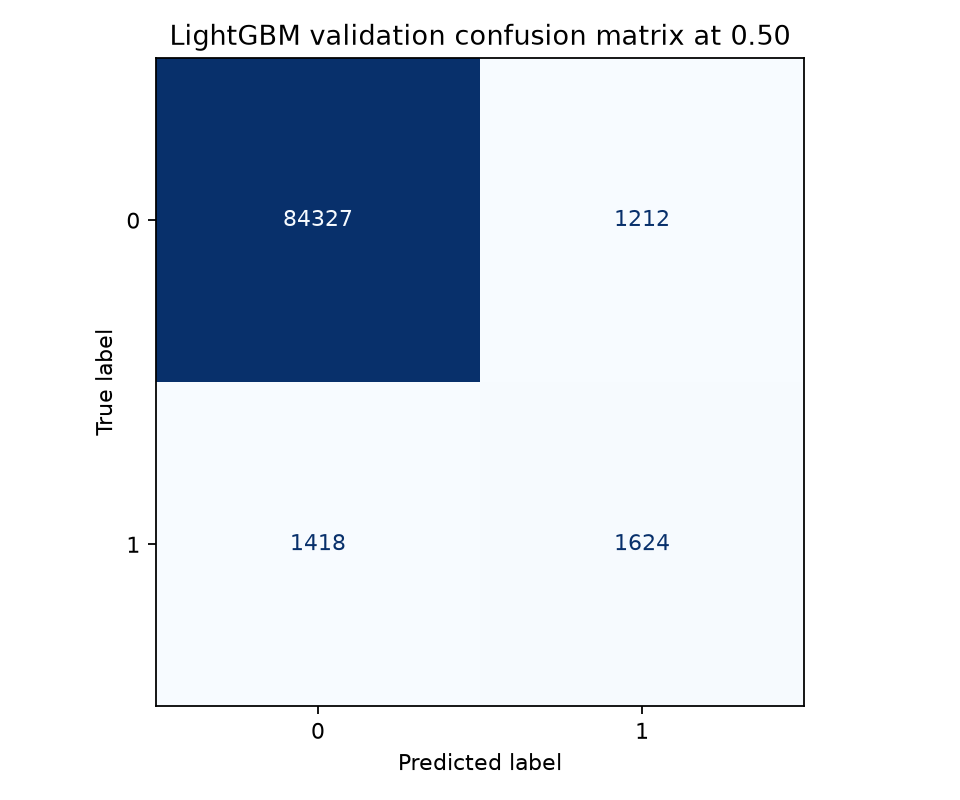

Report: reports\model_comparison_summary.md


In [10]:
figure_paths = save_model_comparison_plots(
    results, y_validation, PROJECT_ROOT / "reports" / "figures"
)
report_path = PROJECT_ROOT / "reports" / "model_comparison_summary.md"
write_model_comparison_report(results, validation_prevalence, grids, report_path, tracking_uri)
for path in figure_paths:
    display(Image(filename=str(path)))
print(f"Report: {report_path.relative_to(PROJECT_ROOT)}")

## 9. Limitations and next-step boundary

- These are baseline models with memory-conscious frequency encoding, not final features.
- Probabilities are not calibrated and the 0.50 threshold is not business-cost optimized.
- No SHAP, graph features, rules, deployment, or production simulation is performed.
- Most importantly, holdout remains untouched and has no reported predictions or metrics.